# Данные Yambda: анализ и подготовка

Посмотрим на журнал, долю прослушивания и события рядом с лайками.
В первой кодовой ячейке `report` показывает сохранённые результаты,
а `recompute` заново готовит данные и строит графики из исходного журнала.


Я выбрал [Yambda flat 50m](https://huggingface.co/datasets/yandex/yambda), потому что в нём есть повторные прослушивания
и явные реакции. Сначала разберусь с данными, затем опишу, как получены метки.

In [1]:
from pathlib import Path
import json
import os
import sys

import pandas as pd
from IPython.display import display

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / 'task_1/src').is_dir() and (path / 'docs/results').is_dir())
TASK = ROOT / 'task_1'
sys.path.insert(0, str(TASK / 'src'))
from notebook_workflow import from_environment

MODE = os.getenv('TLAB_NOTEBOOK_MODE', 'report')  # report или recompute
RUN_NAME = os.getenv('TLAB_NOTEBOOK_RUN', 'repeat_01')
DOWNLOAD_DATA = os.getenv('TLAB_NOTEBOOK_DOWNLOAD', '1') == '1'
INCLUDE_TEST = os.getenv('TLAB_INCLUDE_TEST', '0') == '1'
workflow = from_environment(MODE, RUN_NAME, DOWNLOAD_DATA, INCLUDE_TEST)

workflow.ensure('eda')
EDA = workflow.path('eda')
snapshot = json.loads((EDA / 'snapshot.json').read_text())
print(snapshot['description'])


Сохранённые выводы первичного анализа; новый проход по исходному журналу не выполнялся.


## Какие данные есть

In [2]:
sizes = {name: snapshot[name] for name in
         ['rows', 'users', 'items', 'listen_rows', 'reaction_rows', 'duplicated_rows']}
display(pd.Series(sizes, name='Сохранённое значение').to_frame())
assert sizes['listen_rows'] + sizes['reaction_rows'] == sizes['rows']

,Сохранённое значение
rows,47790449
users,10000
items,934057
listen_rows,46467212
reaction_rows,1323237
duplicated_rows,236230


В журнале 47.79 млн строк, из них 46.47 млн прослушиваний. Повторы строк
не удалял: одинаковые записи могут соответствовать разным событиям.
При подготовке сохраняю исходный порядок строк.

In [3]:
schema = pd.read_csv(EDA / 'schema.csv')
display(schema.rename(columns={
    'column': 'Столбец', 'dtype': 'Тип при анализе', 'missing': 'Пропусков',
    'missing_pct': 'Пропусков, %', 'unique': 'Различных значений',
}))

,Столбец,Тип при анализе,Пропусков,"Пропусков, %",Различных значений
0,uid,uint32,0,0.000,10000
1,timestamp,uint32,0,0.000,5052573
2,item_id,uint32,0,0.000,934057
3,is_organic,uint8,0,0.000,2
4,played_ratio_pct,float64,1323237,2.769,160
5,track_length_seconds,float64,1323237,2.769,499
6,event_type,str,0,0.000,5


У реакций нет доли и длины прослушивания. Поэтому пропуски в этих полях
ожидаемы и сами по себе не означают ошибку. В таблице показаны типы из
первичного анализа; при сохранении истории используются более компактные типы.

## Доля прослушивания

Доля прослушивания, все listen-события


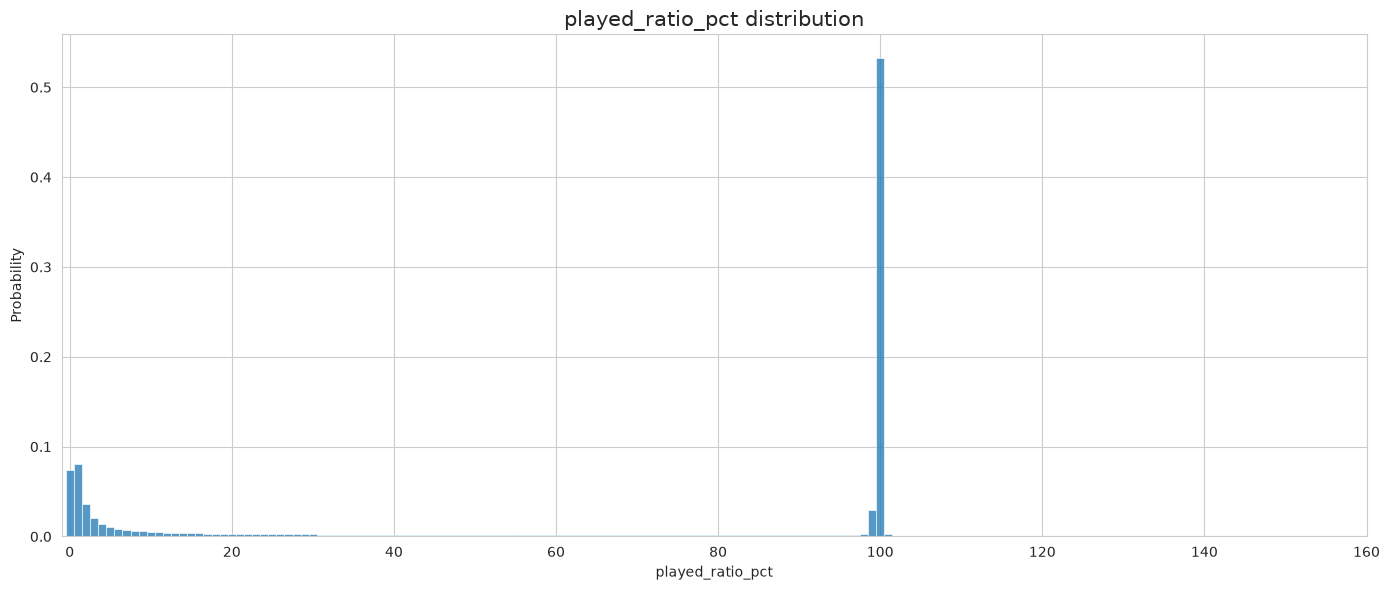

Доля прослушивания: логарифмическая шкала и is_organic


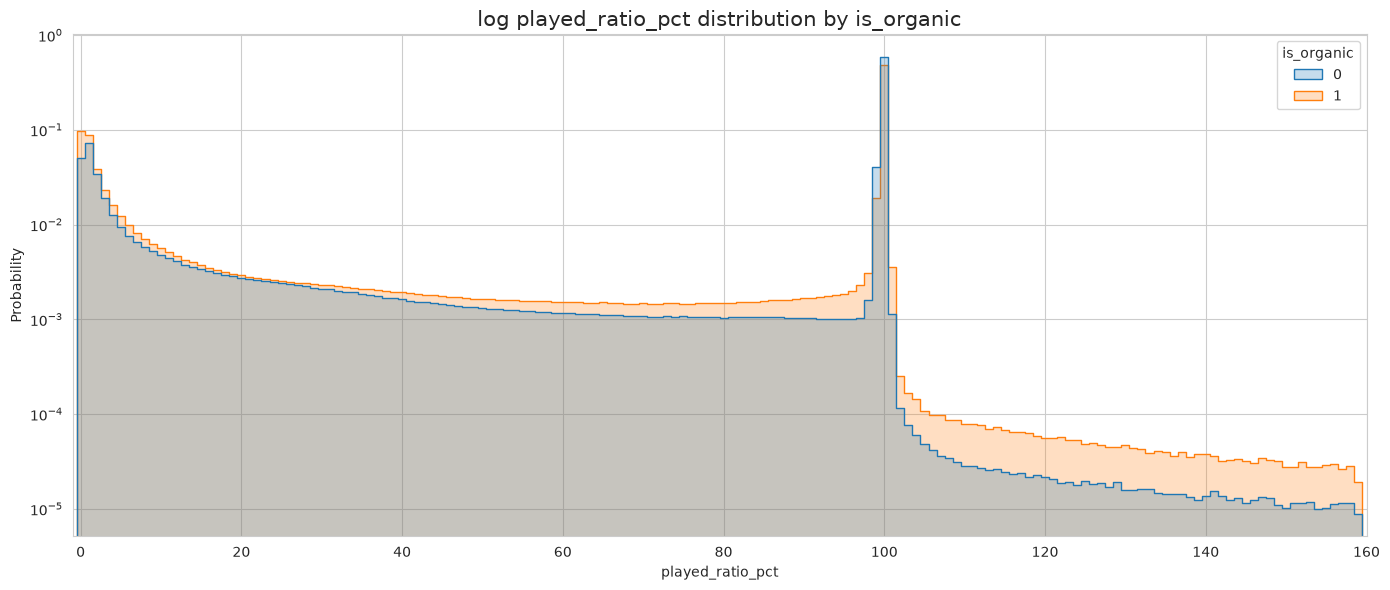

Рекомендованные прослушивания: интервалы по 5 процентных пунктов


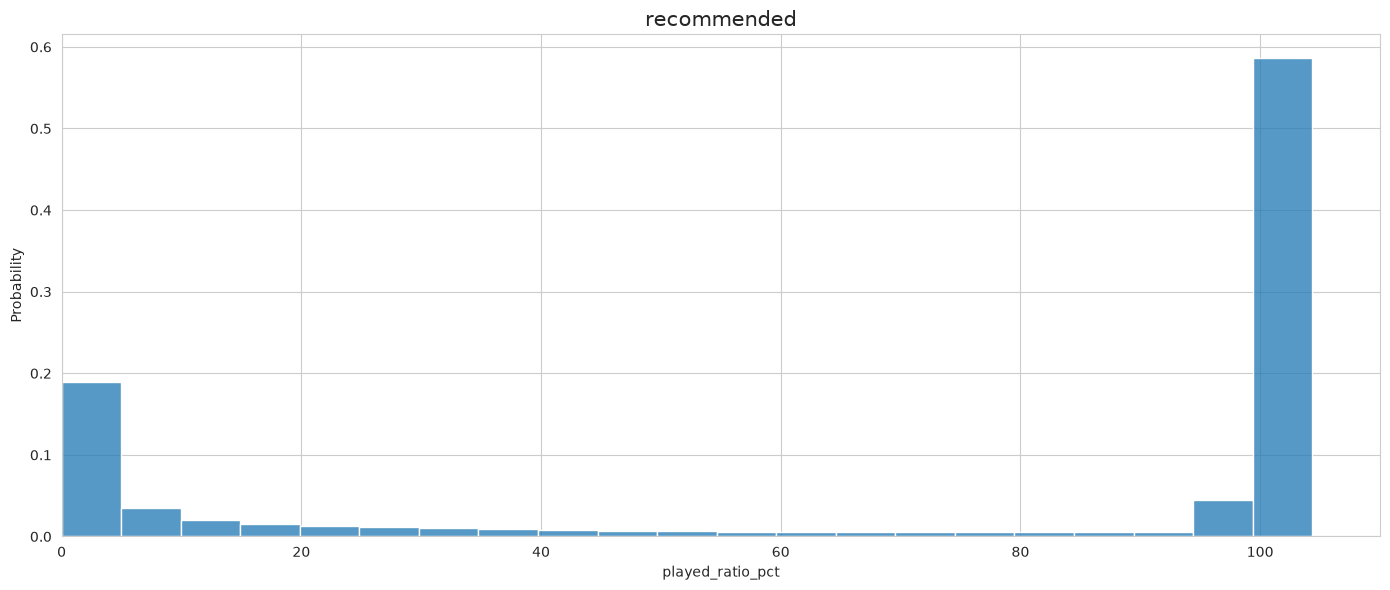

Доля прослушивания у is_organic = 0


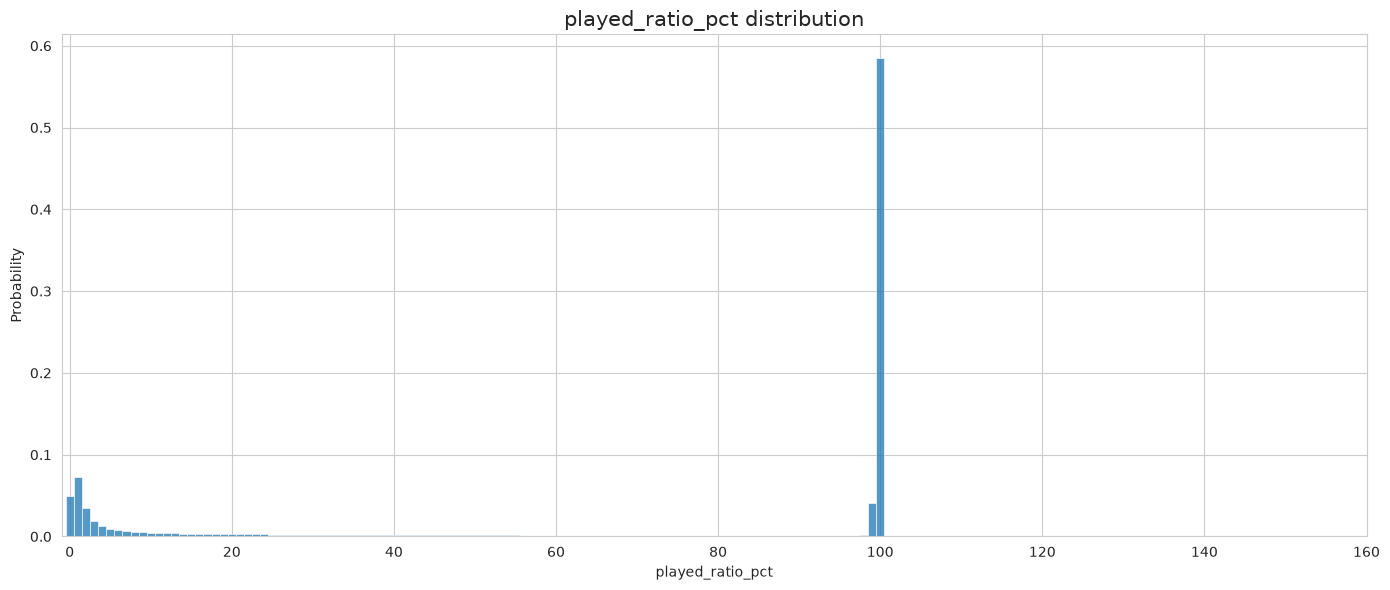

In [4]:
from IPython.display import Image

for image in snapshot['images']:
    if image['source_cell_index'] in (7, 8):
        print(image['caption'])
        display(Image(filename=str(EDA / image['file'])))

Видно два пика: пользователи часто заканчивают слушать в самом начале
или дослушивают почти весь трек. Одно среднее такую форму описывает плохо.
Порог 35% из этих графиков не следует, это выбранная эвристика разметки.

## Лайк и соседние события

Прослушивания в пределах 10 минут от первого лайка пары


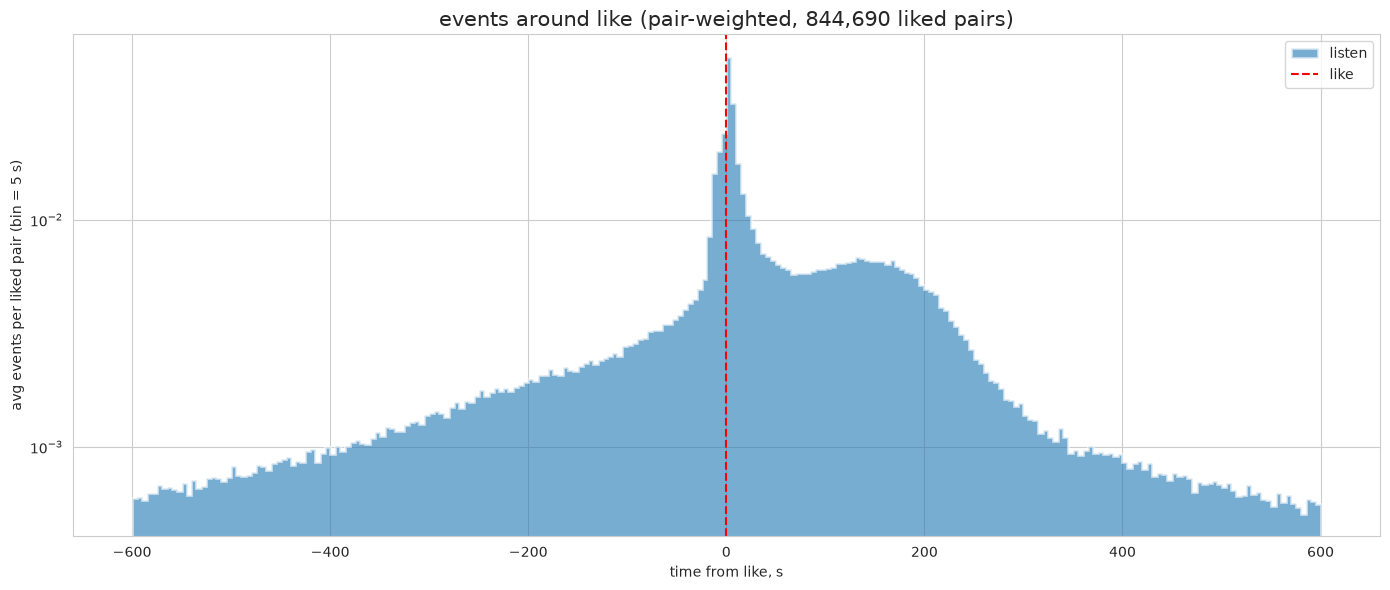

Прослушивания в пределах трёх часов от первого лайка пары


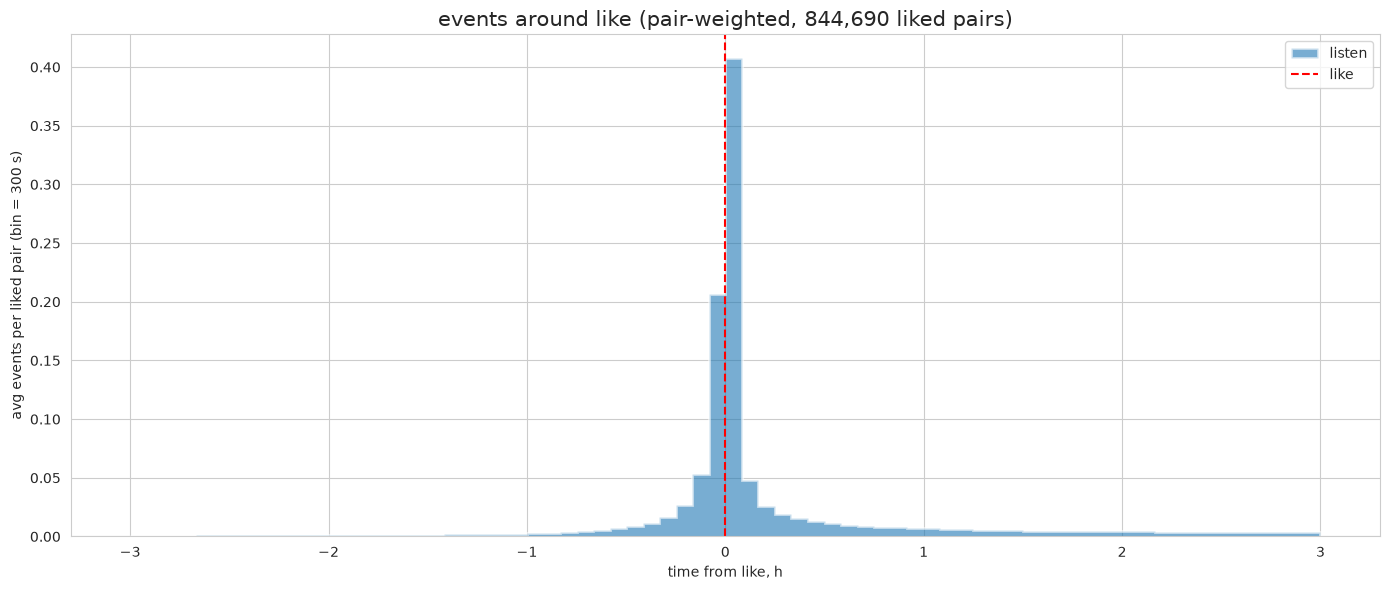

Последующие события относительно первого прослушивания пары


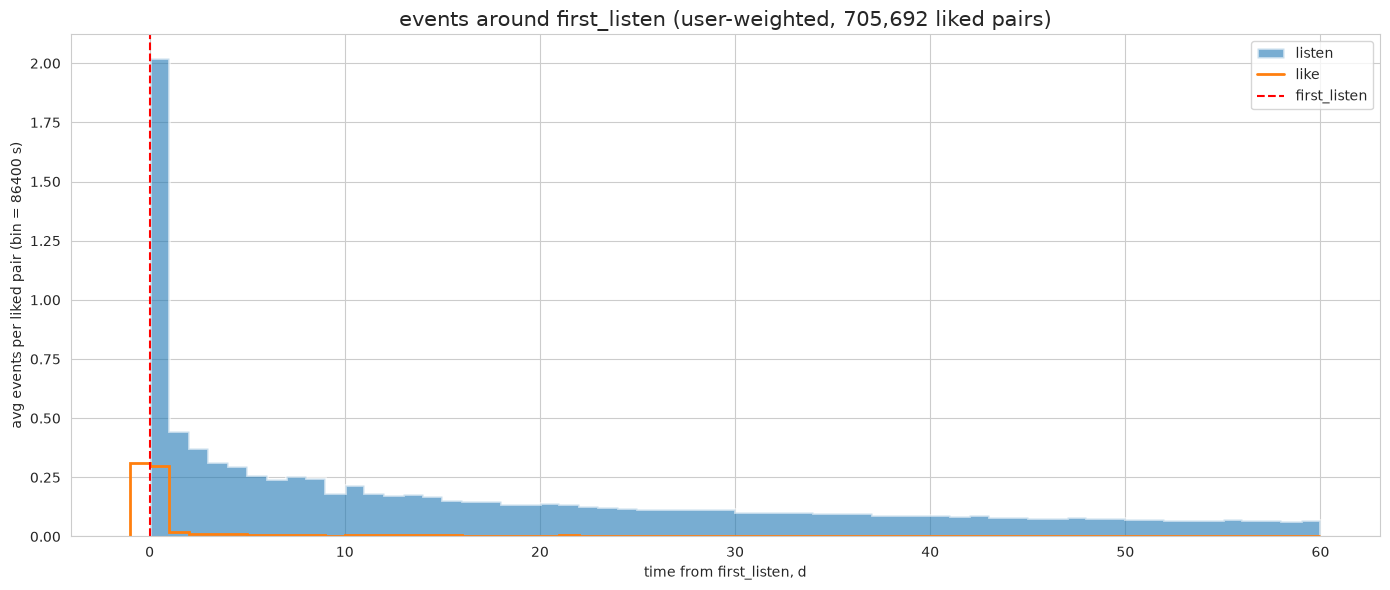

In [5]:
for image in snapshot['images']:
    if image['source_cell_index'] == 17:
        print(image['caption'])
        display(Image(filename=str(EDA / image['file'])))

Рядом с первым лайком пары пользователь–трек много прослушиваний.
Последний график показывает события относительно первого прослушивания
среди пар с лайком. Пользователи имеют одинаковый общий вес.


## Как получена метка

Готовых меток релевантности 0/1/2 здесь нет, поэтому задал следующие правила
в порядке приоритета:

| label | Правило |
| --- | --- |
| 2 | К прослушиванию привязан like |
| 0 | Иначе: dislike или прослушано менее 35% |
| 1 | Остальные прослушивания |

Реакцию привязываю к ближайшему следующему окончанию той же пары, если она
не раньше восстановленного начала. При like и dislike побеждает like.
Unlike и undislike напрямую метку не задают. Такая метка приближает
релевантность, но не измеряет её напрямую.

In [6]:
rules = pd.DataFrame([
    {'Поле': 'start_ts', 'Смысл': 'floor(timestamp - length * ratio / 100 - 5); только старая привязка реакций'},
    {'Поле': 'timestamp', 'Смысл': 'Исходное время события; точная семантика доступности остаётся допущением'},
    {'Поле': 'artist_id', 'Смысл': 'Первый исполнитель в mapping для трека; неизвестный = -1'},
    {'Поле': 'label', 'Смысл': 'Эвристическая метка результата прослушивания'},
])
display(rules)

,Поле,Смысл
0,start_ts,floor(timestamp - length * ratio / 100 - 5); т...
1,timestamp,Исходное время события; точная семантика досту...
2,artist_id,Первый исполнитель в mapping для трека; неизве...
3,label,Эвристическая метка результата прослушивания


## Почему изменилось время запроса

Восстановленный `start_ts` зависит от текущей доли прослушивания.
Его секундный остаток передавал информацию о метке через свежесть.
Поэтому в основном сравнении время запроса взято из прошлого журнала.
[Диагностика](../../docs/start-time-audit.md).


## Подготовка для моделей

`prepare_history.py` сохраняет полную историю и разметку в listens/events.
`prepare_legacy.py` готовит старые samples и ручные признаки.
Нужные этапы вызываются из ноутбуков в режиме `recompute`.

Дальше — [бейзлайны](model-baseline.ipynb).
[Установка и полный запуск](../../docs/reproduction.md).
